In [17]:
# Run first before importing sklearn estimators
from sklearnex import patch_sklearn
patch_sklearn()

# Core library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik

# Library for Data Split and Pipeline Preprocessing
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, StandardScaler, OneHotEncoder, OrdinalEncoder, label_binarize
from sklearn.impute import SimpleImputer

# Library for Models and Metrics
import time
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, average_precision_score, log_loss, confusion_matrix, ConfusionMatrixDisplay,classification_report, roc_auc_score 

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [2]:
# Reload the dataset
file_path = r"./Dataset/my_data.csv"
df = pd.read_csv(file_path)

pd.set_option('display.max_columns', None)

df.head()

,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,last_loan_9,last_loan_8,last_loan_7,last_loan_6,last_loan_5,last_loan_4,last_loan_3,last_loan_2,last_loan_1,credit_score,emi_type,payment_level,payment_volume
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,Standard,1396.14,33.061861,156,Yes,52.138474,44.084010,High_spent_Medium_value_payments,321.019683,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Debt Consolidation Loan,Standard,Non-Negative,High payment,Medium payment
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,Standard,268.81,36.377621,269,Yes,51.934634,39.628311,Low_spent_Small_value_payments,327.009597,No Loan,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Auto Loan,Auto Loan,Standard,Non-Negative,Low payment,Small payment
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,Good,180.70,39.917508,326,No,0.000000,84.774645,High_spent_Small_value_payments,432.727105,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Good,Non-Negative,High payment,Small payment
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,17,17.51,3,Standard,569.11,39.841494,376,Yes,16.941903,41.943603,Low_spent_Medium_value_payments,346.630494,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Personal Loan,Student Loan,Home Equity Loan,Standard,Non-Negative,Low payment,Medium payment
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,20,17.16,6,Bad,3003.45,36.058472,162,Yes,126.596814,67.970377,High_spent_Medium_value_payments,360.325808,No Loan,No Loan,No Loan,No Loan,Auto Loan,Mortgage Loan,Auto Loan,Payday Loan,Not Specified,Poor,Non-Negative,High payment,Medium payment


## Feature Engineering

In [3]:
# Create domain-specific variables
df = df.assign(debt_to_income = lambda x: x['total_emi_per_month']/x['monthly_inhand_salary'], # when x in assign(), x is df
                saving_ratio=lambda x: x['monthly_balance'] / x['monthly_inhand_salary']
)

selected_cols = [f'last_loan_{i}' for i in range(1,10)]

dict_loan = {'count_debt_consolidation_loan': 'Debt Consolidation Loan', 'count_auto_loan' : 'Auto Loan',
                'count_no_loan': 'No Loan', 'count_home_equity_loan': 'Home Equity Loan', 'count_not_specified': 'Not Specified',
                'count_personal_loan': 'Personal Loan', 'count_mortgage_loan': 'Mortgage Loan', 'count_credit_builder_loan': 'Credit Builder Loan', 
                'count_payday_loan':'Payday Loan', 'count_student_loan':'Student Loan'}

for key, value in dict_loan.items():
    df[key] = (df[selected_cols] == value).sum(axis = 1)

active_loan_cols = [
    col for col in dict_loan.keys()
    if col not in ['count_no_loan', 'count_not_specified']
]

df['total_active_loans'] = df[active_loan_cols].sum(axis = 1)

# Binary flag indicators

# Red flag
df['has_payday_loan'] = (df['count_payday_loan'] > 0).astype(int)
df['has_home_equity_loan'] = (df['count_home_equity_loan'] > 0).astype(int)
df['has_mortgage_loan'] = (df['count_mortgage_loan'] > 0).astype(int)

# Green flag
df['has_credit_builder_loan'] = (df['count_credit_builder_loan'] > 0).astype(int)

df['high_risk_loan_ratio'] = (df['count_payday_loan'])/(df['total_active_loans'] + 1)

df = df.drop(columns = selected_cols + ['payment_behaviour'])

df.head()

,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,monthly_balance,credit_score,emi_type,payment_level,payment_volume,debt_to_income,saving_ratio,count_debt_consolidation_loan,count_auto_loan,count_no_loan,count_home_equity_loan,count_not_specified,count_personal_loan,count_mortgage_loan,count_credit_builder_loan,count_payday_loan,count_student_loan,total_active_loans,has_payday_loan,has_home_equity_loan,has_mortgage_loan,has_credit_builder_loan,high_risk_loan_ratio
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,10,9.44,9,Standard,1396.14,33.061861,156,Yes,52.138474,44.084010,321.019683,Standard,Non-Negative,High payment,Medium payment,0.031175,0.191949,2,0,6,1,0,0,0,0,0,0,3,0,1,0,0,0.0
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,8,9.64,2,Standard,268.81,36.377621,269,Yes,51.934634,39.628311,327.009597,Standard,Non-Negative,Low payment,Small payment,0.030808,0.193987,1,2,5,1,0,0,0,0,0,0,4,0,1,0,0,0.0
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,12,8.51,0,Good,180.70,39.917508,326,No,0.000000,84.774645,432.727105,Good,Non-Negative,High payment,Small payment,0.000000,0.168048,0,0,9,0,0,0,0,0,0,0,0,0,0,0,0,0.0
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,17,17.51,3,Standard,569.11,39.841494,376,Yes,16.941903,41.943603,346.630494,Standard,Non-Negative,Low payment,Medium payment,0.014666,0.300071,0,0,6,1,0,1,0,0,0,1,3,0,1,0,0,0.0
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,20,17.16,6,Bad,3003.45,36.058472,162,Yes,126.596814,67.970377,360.325808,Poor,Non-Negative,High payment,Medium payment,0.041522,0.118181,0,2,4,0,1,0,1,0,1,0,4,1,0,1,0,0.2


In [4]:
# Mapping target varible
target_map = {'Poor': 0, 'Standard': 1, 'Good': 2}
df['credit_score'] = df['credit_score'].replace(target_map)

In [5]:
# Check on the values of target variables: Credit_score
print(f'Data type of Credit Score: {df['credit_score'].dtype}\n')
print(f'Unique Values of Credit Score:{df['credit_score'].unique()}\n')
print(f'Number of missing values:{df['credit_score'].isna().sum()}')

Data type of Credit Score: object

Unique Values of Credit Score:[1 2 0]

Number of missing values:0


In [6]:
# Hyperparameter
y = df['credit_score'].astype('int16')
groups = df['customer_id']
X = df.drop(columns = ['credit_score', 'customer_id'])

params = {'random_state': 42}

In [7]:
# Splitting original dataset into Dev and Test set
sgkf_test = StratifiedGroupKFold(n_splits = 5, shuffle = True, random_state = params['random_state'])

dev_idx, test_idx = next(sgkf_test.split(X, y, groups = groups))

X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]
groups_dev = groups.iloc[dev_idx]

# Splitting Dev set into Train set and Validate set
sgkf_val= StratifiedGroupKFold(n_splits = 4, shuffle = True, random_state = params['random_state'])
train_idx, val_idx = next(sgkf_val.split(X_dev, y_dev, groups = groups_dev))

X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

Test Set: 2500
Development Set: 10000
Train Groups: 7500
validate Groups: 2500
There is no duplicated row in Dev and Test Set!
There is no duplicated row in Train and Validate Set!


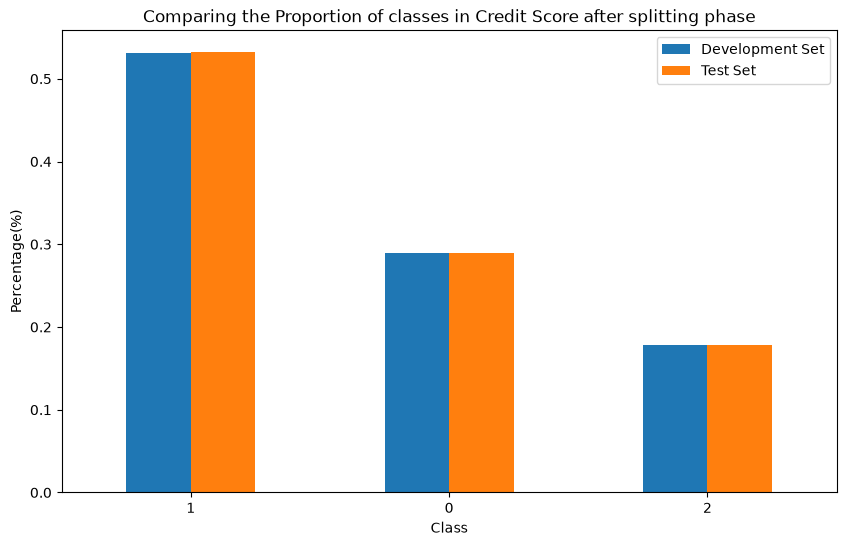

In [8]:
# Check on the validity after spliting
print(f"Test Set: {groups.iloc[test_idx].nunique()}")
print(f"Development Set: {groups.iloc[dev_idx].nunique()}")
print(f"Train Groups: {groups_dev.iloc[train_idx].nunique()}")
print(f"validate Groups: {groups_dev.iloc[val_idx].nunique()}")

test_customers = set(groups.iloc[test_idx])
dev_customers = set(groups.iloc[dev_idx])
train_customers = set(groups_dev.iloc[train_idx])
val_customers = set(groups_dev.iloc[val_idx])

overlap_dev_test = dev_customers.intersection(test_customers)
overlap_train_val = train_customers.intersection(val_customers)

print(f"Numbers of duplications:{len(overlap_dev_test)}") if len(overlap_dev_test) > 0 else print("There is no duplicated row in Dev and Test Set!")
print(f"Numbers of duplications:{len(overlap_train_val)}") if len(overlap_train_val) > 0 else print("There is no duplicated row in Train and Validate Set!")

# Visualization to check whether Dev and Test set have the same proportion in target's classes
dev_counts = y_dev.value_counts(normalize = True)
test_counts = y_test.value_counts(normalize = True)

df_compared = pd.DataFrame({'Development Set':dev_counts, 'Test Set': test_counts})
df_compared.plot(kind = 'bar', figsize =(10,6))

plt.title('Comparing the Proportion of classes in Credit Score after splitting phase')
plt.xlabel('Class')
plt.ylabel('Percentage(%)')
plt.xticks(rotation = 0)

plt.show()

## Pipeline Preprocessing Initialization

In [9]:
# Skewed-right variables

# Only numeric (disc/cont) variables having range > 50 and skewness > 1 (extremely skewed)
dis_ratio_var = ['age', 'num_bank_accounts','num_credit_card','num_of_loan','delay_from_due_date','num_of_delayed_payment',
                    'num_credit_inquiries','credit_history_age','count_debt_consolidation_loan', 'count_auto_loan', 'count_no_loan',
                    'count_home_equity_loan', 'count_not_specified', 'count_personal_loan',
                    'count_mortgage_loan', 'count_credit_builder_loan', 'count_payday_loan',
                    'count_student_loan', 'total_active_loans', 'has_payday_loan',
                    'has_home_equity_loan', 'has_mortgage_loan', 'has_credit_builder_loan']

con_ratio_var = ['annual_income','monthly_inhand_salary','interest_rate','changed_credit_limit','outstanding_debt',
                'credit_utilization_ratio','amount_invested_monthly','monthly_balance', 'debt_to_income',
                'saving_ratio','high_risk_loan_ratio']

numeric_col = dis_ratio_var + con_ratio_var + ['total_emi_per_month']

range_values = X_train[numeric_col].max() - X_train[numeric_col].min()
skew_values = X_train[numeric_col].skew()
skewed_features = skew_values[(range_values > 50) & (skew_values > 1)].index.tolist()

print(f"Variables needing to be log transformed are: {skewed_features}")

# Process with negative values with total_emi_per_month

def replace_negative_emi(X):
    X_copy = np.array(X, copy = True, dtype = float)
    X_copy[X_copy<0] = np.nan
    return X_copy

Variables needing to be log transformed are: ['annual_income', 'monthly_inhand_salary', 'outstanding_debt', 'amount_invested_monthly', 'monthly_balance', 'total_emi_per_month']


In [10]:
# Normal numeric variables
num_cols = [col for col in numeric_col if col not in skewed_features]

# Non-numeric variables
str_cols = X_train.select_dtypes(exclude = 'number').columns.tolist()

credit_mix_ord = ['Bad', 'Standard', 'Good']
payment_level_ord = ['Low payment', 'High payment']
payment_volume_ord = ['Small payment', 'Medium payment', 'Large payment']

nom_cols = ['occupation', 'payment_of_min_amount']

ord_cols = ['credit_mix', 'payment_level', 'payment_volume']

In [11]:
# Create pipeline
nom_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'most_frequent')),
                                 ('onehot', OneHotEncoder(handle_unknown = 'ignore', sparse_output = False))])

ord_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'most_frequent')),
                                 ('custom_mapper', OrdinalEncoder(
                                                    categories = [credit_mix_ord, payment_level_ord, payment_volume_ord],
                                                    handle_unknown = 'use_encoded_value',
                                                    unknown_value = -1))])

yeo_johnson_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'median')),
                                         ('yeo_johnson', PowerTransformer(method = 'yeo-johnson', standardize=True))])

num_pipeline = Pipeline(steps = [('imputer', SimpleImputer(strategy = 'mean')),
                                 ('scaler', StandardScaler())])

negative_emi = Pipeline(steps = [('replacer', FunctionTransformer(replace_negative_emi)),
                                 ('imputer', SimpleImputer(strategy = 'mean')),
                                 ('yeo_johnson', PowerTransformer(method = 'yeo-johnson', standardize=True))])

preprocessor = ColumnTransformer(
    transformers = [
        ('nom_branch', nom_pipeline, nom_cols),
        ('ord_branch', ord_pipeline, ord_cols),
        ('yeo_johnson_branch', yeo_johnson_pipeline, skewed_features),
        ('num_branch', num_pipeline, num_cols),
        ('negative_emi_branch',negative_emi, ['total_emi_per_month'] )
    ],
    remainder = 'drop'
)

In [12]:
models = {
    "Most Frequent (Baseline)": DummyClassifier(
        strategy = "most_frequent"
    ),
    "Logistic Regression": LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=params['random_state']
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=params['random_state'],
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=params['random_state']
    ),
    "LightGBM": LGBMClassifier(
        objective='multiclass',
        class_weight='balanced',
        random_state=params['random_state'],
        n_jobs=-1,
        verbose=-1
    ),
    "XGBoost": XGBClassifier(
        objective='multi:softprob',
        random_state=params['random_state'],
        n_jobs=-1,
        eval_metric='mlogloss'
    )
}


full_pipeline = Pipeline(steps = [
    ('preprocessing', preprocessor),
    ('classifier', models)
])

In [15]:
rows = []
for name, clf in models.items():
    print(f"Training and Evaluating with {name}")
    pipe = Pipeline([('preprocessing', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_val)
    proba = pipe.predict_proba(X_val)
    proba = proba / proba.sum(axis=1, keepdims=True)
    classes = pipe.classes_

    rows.append({
        'Model':     name,
        'F1-Micro':  f1_score(y_val, pred, average='micro'),
        'F1-Macro':  f1_score(y_val, pred, average='macro'),
        'Precision': precision_score(y_val, pred, average='macro'),
        'Recall':    recall_score(y_val, pred, average='macro'),
        'ROC-AUC':   roc_auc_score(y_val, proba, multi_class='ovr'),
        'PR-AUC':    average_precision_score(label_binarize(y_val, classes=classes), proba),
        'Log-loss':  log_loss(y_val, proba, labels=classes),
    })

df_benchmark = pd.DataFrame(rows).sort_values('F1-Macro', ascending=False).reset_index(drop=True)

df_benchmark

Training and Evaluating with Most Frequent (Baseline)


d:\Installations\Miniconda\envs\data_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Training and Evaluating with Logistic Regression
Training and Evaluating with Random Forest
Training and Evaluating with Extra Trees
Training and Evaluating with LightGBM
Training and Evaluating with XGBoost


,Model,F1-Micro,F1-Macro,Precision,Recall,ROC-AUC,PR-AUC,Log-loss
0,LightGBM,0.69090,0.683233,0.671290,0.723975,0.849220,0.712601,0.716070
1,Random Forest,0.68110,0.675250,0.666407,0.724190,0.838773,0.697625,0.768841
2,Extra Trees,0.67480,0.668465,0.661484,0.718821,0.830832,0.686869,0.782683
3,XGBoost,0.69215,0.663527,0.668818,0.659033,0.841406,0.699904,0.699841
4,Logistic Regression,0.65660,0.650473,0.642540,0.699015,0.809395,0.657503,0.819255
5,Most Frequent (Baseline),0.53175,0.231435,0.177250,0.333333,0.500000,0.333333,16.877441


In [ ]:
# cm = confusion_matrix(y_val, y_val_pred)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm)
# disp.plot()
# plt.show()
# print("Classification Report for Evaluation")
# print(classification_report(y_val, y_val_pred))

In [21]:
best_model = 'LightGBM'

final_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', models[best_model]),   # lấy 1 model ra khỏi dict
])

In [22]:
# Final trên tập dev để có nhiều sample
final_pipeline.fit(X_dev, y_dev)
y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)
y_test_proba = y_test_proba / y_test_proba.sum(axis=1, keepdims=True)

print("Classification Report for Final Test")
print(classification_report(y_test, y_test_pred))

auc_score = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='macro')
print(f"Test ROC-AUC (Macro OvR): {auc_score:.4f}")

Classification Report for Final Test
              precision    recall  f1-score   support

           0       0.67      0.74      0.70      5798
           1       0.83      0.62      0.71     10635
           2       0.52      0.82      0.63      3567

    accuracy                           0.69     20000
   macro avg       0.67      0.72      0.68     20000
weighted avg       0.73      0.69      0.69     20000

Test ROC-AUC (Macro OvR): 0.8459


### Correlation between type of feature variables and target variable

In [ ]:
# # Prepare dataframe for creating heatmaps
# all_numeric_cols = [
#     'credit_score', 'credit_mix', 'payment_level', 'payment_volume', 
#     'annual_income', 'monthly_inhand_salary', 'outstanding_debt', 'delay_from_due_date', 
#     'credit_utilization_ratio', 'num_of_delayed_payment', 
#     'credit_history_age', 'total_emi_per_month', 'amount_invested_monthly'
# ]

# spearman_corr = df[all_numeric_cols].corr(method='spearman')

# plt.figure(figsize=(10, 8))
# sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
# plt.title("Unified Spearman Correlation Heatmap", fontsize=14, fontweight='bold')
# plt.tight_layout()
# plt.show()

# # Target correlation plot

# target_corr = spearman_corr[['credit_score']].drop(index = 'credit_score').sort_values(by = 'credit_score', ascending = False)
# plt.figure(figsize=(8,6))

# sns.barplot(data = target_corr, x = 'credit_score', y = target_corr.index, palette = 'coolwarm', hue = target_corr.index)
# plt.title("Spearman Correlation of Features with Credit Score")
# plt.xlabel("Spearman Correlation Coefficients")
# plt.ylabel("Feature variable")

# plt.grid(True, linestyle = '-.', alpha = 0.75)
# plt.show()

# # Using phik to check correlation between nominal and target variables

# phik_temp1 = df[['credit_score', 'payment_volume', 'payment_level', 'credit_mix']]
# phik_temp2 = df[['occupation', 'payment_behaviour']]
# phik_matrix = pd.concat([phik_temp1, phik_temp2], axis = 1).phik_matrix()

# plt.figure(figsize = (8, 5))
# sns.heatmap(data = phik_matrix, annot = True, fmt = '.2f', cmap = 'Blues')
# plt.title('Phik Correlation Heatmap between Categorical and Target variable', fontweight = 'bold')
# plt.show()